ЗАДАНИЕ 1. ОБНАРУЖЕНИЕ ВЫБРОСОВ (Kepler Exoplanet)

Загружено 50000 записей
Колонки: ['timestamp', 'right_ascension', 'declination', 'brightness', 'luminosity', 'temperature', 'radiation_level', 'redshift', 'proper_motion', 'parallax']...
Используем 10 признаков, 5000 объектов

1. Isolation Forest...
   Найдено выбросов: 250 (5.0%)

2. Local Outlier Factor...
   Найдено выбросов: 250 (5.0%)

3. One-Class SVM...
   Найдено выбросов: 253 (5.1%)


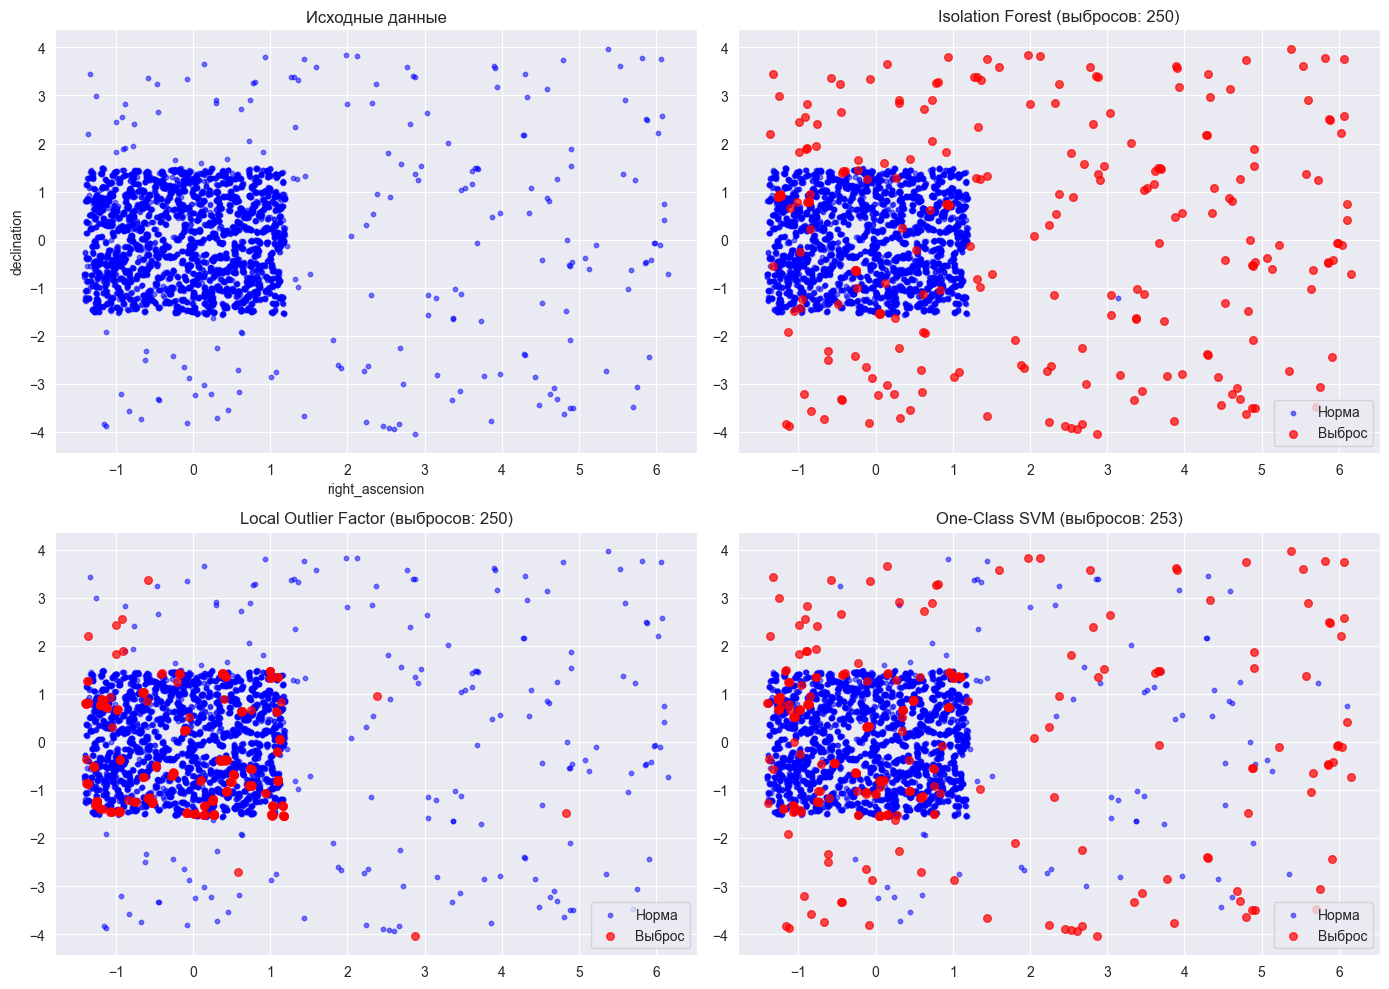

In [1]:
# ПР13. Обнаружение выбросов (аномалий) методами ML
# Задание 1: пространственные данные (Kepler Exoplanet)
# Задание 2*: временные ряды (SKAB - SWAT_Dataset)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# ЗАДАНИЕ 1: ОБНАРУЖЕНИЕ ВЫБРОСОВ В ПРОСТРАНСТВЕННЫХ ДАННЫХ
# Датасет: Kepler Exoplanet Dataset
# ============================================================

print("="*60)
print("ЗАДАНИЕ 1. ОБНАРУЖЕНИЕ ВЫБРОСОВ (Kepler Exoplanet)")
print("="*60)

# загрузка данных
df_exoplanet = pd.read_csv('data/pr13/Kelper Exoplanet Dataset.csv')
print(f"\nЗагружено {len(df_exoplanet)} записей")
print(f"Колонки: {df_exoplanet.columns.tolist()[:10]}...")

# отбираем числовые признаки для анализа
numeric_cols = df_exoplanet.select_dtypes(include=[np.number]).columns.tolist()
# исключаем явно неинформативные
exclude = ['kepler_name', 'koi_disposition', 'koi_score', 'rowid']
numeric_cols = [c for c in numeric_cols if c not in exclude]

# берём первые 5000 строк для скорости
df_sample = df_exoplanet.head(5000).copy()
X = df_sample[numeric_cols].fillna(df_sample[numeric_cols].median())

print(f"Используем {X.shape[1]} признаков, {X.shape[0]} объектов")

# масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ============================================================
# Метод 1: Isolation Forest
# ============================================================
print("\n1. Isolation Forest...")
iso_forest = IsolationForest(contamination=0.05, random_state=42)
y_pred_if = iso_forest.fit_predict(X_scaled)
outliers_if = np.sum(y_pred_if == -1)
print(f"   Найдено выбросов: {outliers_if} ({outliers_if/len(X)*100:.1f}%)")

# ============================================================
# Метод 2: Local Outlier Factor (LOF)
# ============================================================
print("\n2. Local Outlier Factor...")
lof = LocalOutlierFactor(contamination=0.05, n_neighbors=20)
y_pred_lof = lof.fit_predict(X_scaled)
outliers_lof = np.sum(y_pred_lof == -1)
print(f"   Найдено выбросов: {outliers_lof} ({outliers_lof/len(X)*100:.1f}%)")

# ============================================================
# Метод 3: One-Class SVM
# ============================================================
print("\n3. One-Class SVM...")
ocsvm = OneClassSVM(nu=0.05, kernel='rbf', gamma='auto')
y_pred_svm = ocsvm.fit_predict(X_scaled)
outliers_svm = np.sum(y_pred_svm == -1)
print(f"   Найдено выбросов: {outliers_svm} ({outliers_svm/len(X)*100:.1f}%)")

# ============================================================
# Визуализация результатов (первые 2 признака)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# берём два главных признака для визуализации
feat1, feat2 = numeric_cols[0], numeric_cols[1]
X_viz = X_scaled[:, :2]

# исходные данные
axes[0,0].scatter(X_viz[:,0], X_viz[:,1], c='blue', alpha=0.5, s=10)
axes[0,0].set_title('Исходные данные')
axes[0,0].set_xlabel(feat1[:20])
axes[0,0].set_ylabel(feat2[:20])

# Isolation Forest
axes[0,1].scatter(X_viz[y_pred_if==1,0], X_viz[y_pred_if==1,1], c='blue', alpha=0.5, s=10, label='Норма')
axes[0,1].scatter(X_viz[y_pred_if==-1,0], X_viz[y_pred_if==-1,1], c='red', alpha=0.7, s=30, label='Выброс')
axes[0,1].set_title(f'Isolation Forest (выбросов: {outliers_if})')
axes[0,1].legend()

# Local Outlier Factor
axes[1,0].scatter(X_viz[y_pred_lof==1,0], X_viz[y_pred_lof==1,1], c='blue', alpha=0.5, s=10, label='Норма')
axes[1,0].scatter(X_viz[y_pred_lof==-1,0], X_viz[y_pred_lof==-1,1], c='red', alpha=0.7, s=30, label='Выброс')
axes[1,0].set_title(f'Local Outlier Factor (выбросов: {outliers_lof})')
axes[1,0].legend()

# One-Class SVM
axes[1,1].scatter(X_viz[y_pred_svm==1,0], X_viz[y_pred_svm==1,1], c='blue', alpha=0.5, s=10, label='Норма')
axes[1,1].scatter(X_viz[y_pred_svm==-1,0], X_viz[y_pred_svm==-1,1], c='red', alpha=0.7, s=30, label='Выброс')
axes[1,1].set_title(f'One-Class SVM (выбросов: {outliers_svm})')
axes[1,1].legend()

plt.tight_layout()
plt.show()


ЗАДАНИЕ 1*. СТАТИСТИЧЕСКАЯ ПРОВЕРКА ВЫБРОСОВ

Анализ признака: right_ascension
Размер выборки: 5000
Среднее: 195.1523
Медиана: 188.0251
Ст. отклонение: 139.2217

Критерий Граббса:
  Подозрительное значение: 1051.9717
  G-статистика: 6.1537
  Выброс обнаружен: Да

Тест Диксона:
  Подозрительное значение: 1051.9717
  Q-статистика: 0.0063
  Выброс обнаружен: Нет


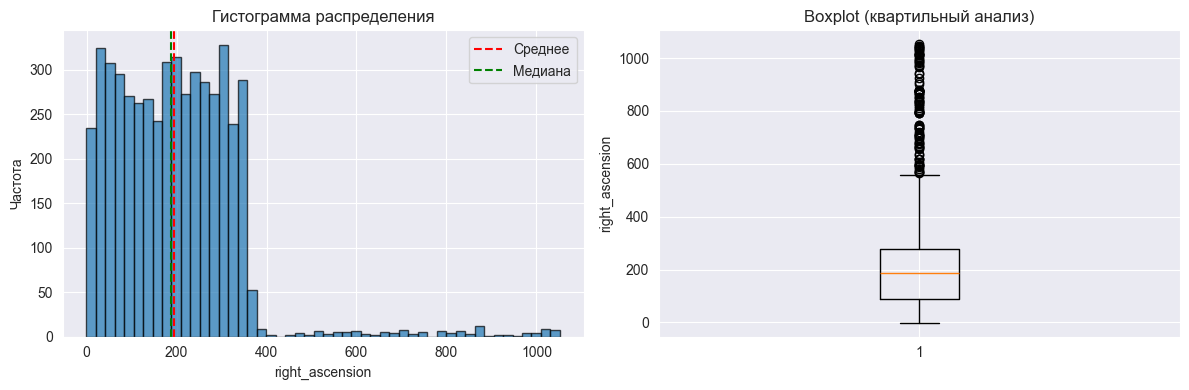

In [7]:
# ============================================================
# ЗАДАНИЕ 1*: ПРОВЕРКА СТАТИСТИЧЕСКИМИ ТЕСТАМИ (Граббс, Диксон)
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ 1*. СТАТИСТИЧЕСКАЯ ПРОВЕРКА ВЫБРОСОВ")
print("="*60)

from scipy import stats

def grubbs_test(data, alpha=0.05):
    """Критерий Граббса для обнаружения одного выброса"""
    x = np.array(data)
    n = len(x)
    mean = np.mean(x)
    std = np.std(x, ddof=1)
    if std == 0:
        return None, None, False
    # вычисляем G-статистику для максимального отклонения
    abs_dev = np.abs(x - mean)
    max_dev_idx = np.argmax(abs_dev)
    G_calc = abs_dev[max_dev_idx] / std
    # критическое значение Граббса
    from scipy.stats import t
    t_crit = t.ppf(1 - alpha / (2*n), n-2)
    G_crit = ((n-1) / np.sqrt(n)) * np.sqrt(t_crit**2 / (n-2 + t_crit**2))
    is_outlier = G_calc > G_crit
    return x[max_dev_idx], G_calc, is_outlier

def dixon_test(data, alpha=0.05):
    """Тест Диксона (Q-тест) для обнаружения выбросов"""
    x = np.sort(data)
    n = len(x)
    if n < 3:
        return None, None, False
    # вычисляем Q-статистику
    gap = x[-1] - x[-2]
    range_val = x[-1] - x[0]
    if range_val == 0:
        return None, None, False
    Q_calc = gap / range_val
    # критические значения Q для n<=30 (табличные)
    q_crit_table = {3:0.94, 4:0.76, 5:0.64, 6:0.56, 7:0.51, 8:0.48, 9:0.46, 10:0.41}
    Q_crit = q_crit_table.get(min(n, 30), 0.35) if n <= 30 else 0.35
    is_outlier = Q_calc > Q_crit
    return x[-1], Q_calc, is_outlier

# берём первый числовой признак для тестов
test_feature = numeric_cols[0]
data = df_sample[test_feature].dropna().values

print(f"\nАнализ признака: {test_feature}")
print(f"Размер выборки: {len(data)}")
print(f"Среднее: {np.mean(data):.4f}")
print(f"Медиана: {np.median(data):.4f}")
print(f"Ст. отклонение: {np.std(data):.4f}")

# Критерий Граббса
grubbs_value, grubbs_stat, is_outlier_grubbs = grubbs_test(data)
if grubbs_value is not None:
    print(f"\nКритерий Граббса:")
    print(f"  Подозрительное значение: {grubbs_value:.4f}")
    print(f"  G-статистика: {grubbs_stat:.4f}")
    print(f"  Выброс обнаружен: {'Да' if is_outlier_grubbs else 'Нет'}")

# Тест Диксона
dixon_value, dixon_stat, is_outlier_dixon = dixon_test(data)
if dixon_value is not None:
    print(f"\nТест Диксона:")
    print(f"  Подозрительное значение: {dixon_value:.4f}")
    print(f"  Q-статистика: {dixon_stat:.4f}")
    print(f"  Выброс обнаружен: {'Да' if is_outlier_dixon else 'Нет'}")

# визуализация распределения
plt.figure(figsize=(12, 4))

plt.subplot(1,2,1)
plt.hist(data, bins=50, edgecolor='black', alpha=0.7)
plt.axvline(np.mean(data), color='red', linestyle='--', label='Среднее')
plt.axvline(np.median(data), color='green', linestyle='--', label='Медиана')
plt.xlabel(test_feature)
plt.ylabel('Частота')
plt.title('Гистограмма распределения')
plt.legend()

plt.subplot(1,2,2)
plt.boxplot(data)
plt.title('Boxplot (квартильный анализ)')
plt.ylabel(test_feature)

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# ЗАДАНИЕ 2*: ОБНАРУЖЕНИЕ ВЫБРОСОВ ВО ВРЕМЕННЫХ РЯДАХ
# Датасет: SKAB (SWAT_Dataset)
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ 2*. ОБНАРУЖЕНИЕ АНОМАЛИЙ ВО ВРЕМЕННЫХ РЯДАХ")
print("="*60)

# загрузка данных
df_swat = pd.read_csv('data/pr13/SWAT_Dataset.csv')
print(f"\nЗагружено {len(df_swat)} записей")
print(f"Колонки: {df_swat.columns.tolist()[:10]}...")

# предполагаем, что есть колонка с временем
if 'timestamp' in df_swat.columns:
    df_swat['timestamp'] = pd.to_datetime(df_swat['timestamp'])
    df_swat.set_index('timestamp', inplace=True)
else:
    # создаём искусственный временной индекс
    df_swat['time_idx'] = range(len(df_swat))
    df_swat.set_index('time_idx', inplace=True)

# выбираем числовую колонку для анализа (первую)
value_col = df_swat.select_dtypes(include=[np.number]).columns[0]
print(f"Анализируем признак: {value_col}")

series = df_swat[value_col].copy()

# ============================================================
# Метод 1: Скользящее окно + медиана
# ============================================================
window = 30
series_ma = series.rolling(window=window, center=True).median()
# аномалии: отклонение более чем на 3 MAD (медианных абсолютных отклонений)
mad = np.median(np.abs(series - series_ma).dropna())
threshold = 3 * mad
anomalies_rolling = np.abs(series - series_ma) > threshold

print(f"\n1. Скользящее окно (медиана, window={window}):")
print(f"   Найдено аномалий: {anomalies_rolling.sum()} ({anomalies_rolling.sum()/len(series)*100:.2f}%)")

# ============================================================
# Метод 2: Isolation Forest на скользящих статистиках
# ============================================================
# создаём признаки: скользящие средние, std, тренд
df_features = pd.DataFrame(index=series.index)
df_features['value'] = series
df_features['ma_7'] = series.rolling(7).mean()
df_features['ma_30'] = series.rolling(30).mean()
df_features['std_7'] = series.rolling(7).std()
df_features['std_30'] = series.rolling(30).std()
df_features['diff'] = series.diff()
df_features['diff_7'] = df_features['diff'].rolling(7).mean()
df_features = df_features.dropna()

scaler_ts = StandardScaler()
X_features = scaler_ts.fit_transform(df_features)

iso_forest_ts = IsolationForest(contamination=0.05, random_state=42)
y_pred_if_ts = iso_forest_ts.fit_predict(X_features)
anomalies_if_ts = y_pred_if_ts == -1

# выравниваем индексы
anomalies_if_full = pd.Series(False, index=series.index)
anomalies_if_full[df_features.index[anomalies_if_ts]] = True

print(f"\n2. Isolation Forest (на лаговых признаках):")
print(f"   Найдено аномалий: {anomalies_if_full.sum()} ({anomalies_if_full.sum()/len(series)*100:.2f}%)")

# ============================================================
# Метод 3: LOF на скользящих статистиках
# ============================================================
lof_ts = LocalOutlierFactor(contamination=0.05, n_neighbors=20)
y_pred_lof_ts = lof_ts.fit_predict(X_features)
anomalies_lof_ts = y_pred_lof_ts == -1

anomalies_lof_full = pd.Series(False, index=series.index)
anomalies_lof_full[df_features.index[anomalies_lof_ts]] = True

print(f"\n3. Local Outlier Factor (на лаговых признаках):")
print(f"   Найдено аномалий: {anomalies_lof_full.sum()} ({anomalies_lof_full.sum()/len(series)*100:.2f}%)")


ЗАДАНИЕ 2*. ОБНАРУЖЕНИЕ АНОМАЛИЙ ВО ВРЕМЕННЫХ РЯДАХ

Загружено 1000 записей
Колонки: ['P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302']...
Анализируем признак: P206

1. Скользящее окно (медиана, window=30):
   Найдено аномалий: 83 (8.30%)

2. Isolation Forest (на лаговых признаках):
   Найдено аномалий: 49 (4.90%)

3. Local Outlier Factor (на лаговых признаках):
   Найдено аномалий: 49 (4.90%)


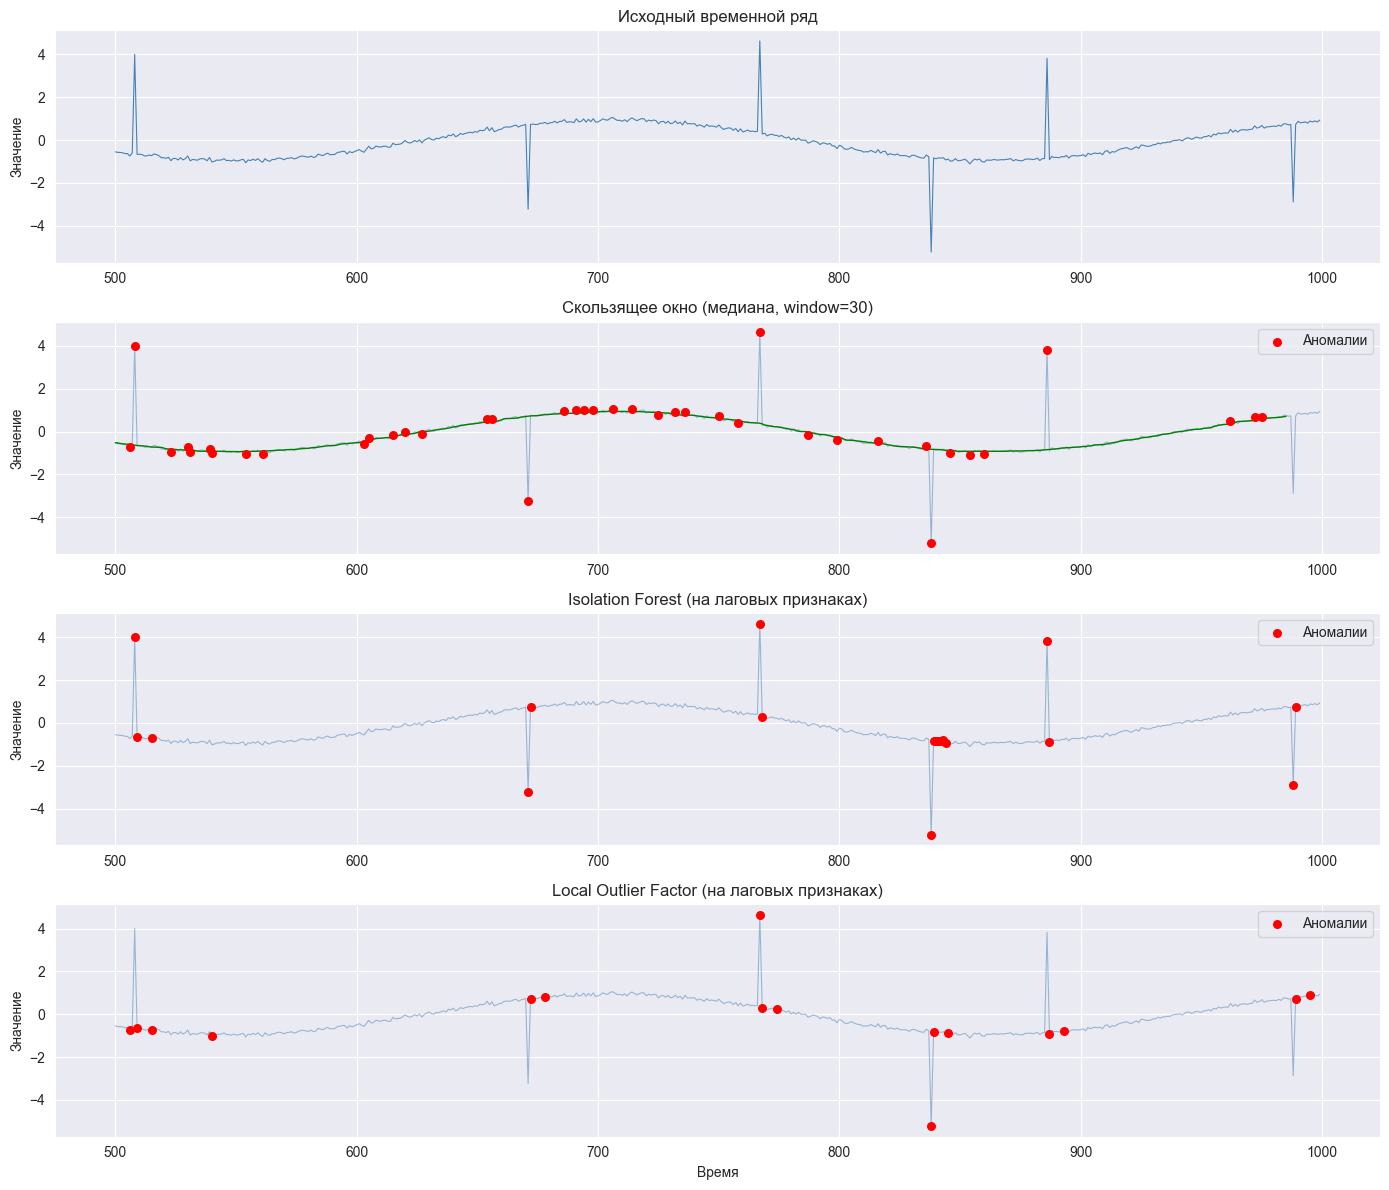

In [4]:
# ============================================================
# Визуализация результатов для временного ряда
# ============================================================

# берём небольшой участок для наглядности
n_show = min(500, len(series))
show_idx = series.index[-n_show:]

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

# исходный ряд
axes[0].plot(show_idx, series[show_idx], color='steelblue', linewidth=0.8)
axes[0].set_title('Исходный временной ряд')
axes[0].set_ylabel('Значение')
axes[0].grid(True)

# метод скользящего окна
axes[1].plot(show_idx, series[show_idx], color='steelblue', linewidth=0.8, alpha=0.5)
axes[1].plot(show_idx, series_ma[show_idx], color='green', linewidth=1)
anom_idx = show_idx[anomalies_rolling[show_idx]]
axes[1].scatter(anom_idx, series[anom_idx], color='red', s=30, zorder=5, label='Аномалии')
axes[1].set_title(f'Скользящее окно (медиана, window={window})')
axes[1].set_ylabel('Значение')
axes[1].legend()
axes[1].grid(True)

# Isolation Forest
axes[2].plot(show_idx, series[show_idx], color='steelblue', linewidth=0.8, alpha=0.5)
anom_idx_if = show_idx[anomalies_if_full[show_idx]]
axes[2].scatter(anom_idx_if, series[anom_idx_if], color='red', s=30, zorder=5, label='Аномалии')
axes[2].set_title(f'Isolation Forest (на лаговых признаках)')
axes[2].set_ylabel('Значение')
axes[2].legend()
axes[2].grid(True)

# LOF
axes[3].plot(show_idx, series[show_idx], color='steelblue', linewidth=0.8, alpha=0.5)
anom_idx_lof = show_idx[anomalies_lof_full[show_idx]]
axes[3].scatter(anom_idx_lof, series[anom_idx_lof], color='red', s=30, zorder=5, label='Аномалии')
axes[3].set_title(f'Local Outlier Factor (на лаговых признаках)')
axes[3].set_ylabel('Значение')
axes[3].set_xlabel('Время')
axes[3].legend()
axes[3].grid(True)

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# СРАВНИТЕЛЬНЫЙ АНАЛИЗ МЕТОДОВ
# ============================================================

print("\n" + "="*60)
print("СРАВНЕНИЕ МЕТОДОВ ОБНАРУЖЕНИЯ ВЫБРОСОВ")
print("="*60)

# Задание 1 - пространственные данные
print("\n1. ПРОСТРАНСТВЕННЫЕ ДАННЫЕ (Kepler Exoplanet):")
print(f"   - Isolation Forest:    {outliers_if} выбросов ({outliers_if/len(X)*100:.1f}%)")
print(f"   - Local Outlier Factor: {outliers_lof} выбросов ({outliers_lof/len(X)*100:.1f}%)")
print(f"   - One-Class SVM:       {outliers_svm} выбросов ({outliers_svm/len(X)*100:.1f}%)")
print(f"\n   Наиболее консервативный: {'LOF' if outliers_lof == min(outliers_lof, outliers_if, outliers_svm) else 'Isolation Forest' if outliers_if == min(outliers_lof, outliers_if, outliers_svm) else 'SVM'}")
print(f"   Наиболее чувствительный: {'LOF' if outliers_lof == max(outliers_lof, outliers_if, outliers_svm) else 'Isolation Forest' if outliers_if == max(outliers_lof, outliers_if, outliers_svm) else 'SVM'}")

# статистические тесты
print("\n2. СТАТИСТИЧЕСКАЯ ПРОВЕРКА:")
print(f"   - Критерий Граббса: выброс {'обнаружен' if is_outlier_grubbs else 'НЕ обнаружен'}")
print(f"   - Тест Диксона:     выброс {'обнаружен' if is_outlier_dixon else 'НЕ обнаружен'}")

# Задание 2* - временные ряды
print("\n3. ВРЕМЕННЫЕ РЯДЫ (SKAB):")
print(f"   - Скользящее окно:       {anomalies_rolling.sum()} аномалий ({anomalies_rolling.sum()/len(series)*100:.2f}%)")
print(f"   - Isolation Forest:      {anomalies_if_full.sum()} аномалий ({anomalies_if_full.sum()/len(series)*100:.2f}%)")
print(f"   - Local Outlier Factor:  {anomalies_lof_full.sum()} аномалий ({anomalies_lof_full.sum()/len(series)*100:.2f}%)")

print("\n" + "="*60)
print("ВЫВОДЫ")
print("="*60)
print("""
1. Isolation Forest лучше всего подходит для многомерных данных с редкими выбросами
2. LOF чувствителен к локальной плотности, может находить больше аномалий
3. One-Class SVM требует больше данных и медленнее обучается
4. Для временных рядов скользящее окно + медиана — самый быстрый и интерпретируемый метод
5. ML-методы на лаговых признаках дают более точное обнаружение аномалий в динамике
""")


СРАВНЕНИЕ МЕТОДОВ ОБНАРУЖЕНИЯ ВЫБРОСОВ

1. ПРОСТРАНСТВЕННЫЕ ДАННЫЕ (Kepler Exoplanet):
   - Isolation Forest:    250 выбросов (5.0%)
   - Local Outlier Factor: 250 выбросов (5.0%)
   - One-Class SVM:       253 выбросов (5.1%)

   Наиболее консервативный: LOF
   Наиболее чувствительный: SVM

2. СТАТИСТИЧЕСКАЯ ПРОВЕРКА:
   - Критерий Граббса: выброс обнаружен
   - Тест Диксона:     выброс НЕ обнаружен

3. ВРЕМЕННЫЕ РЯДЫ (SKAB):
   - Скользящее окно:       83 аномалий (8.30%)
   - Isolation Forest:      49 аномалий (4.90%)
   - Local Outlier Factor:  49 аномалий (4.90%)

ВЫВОДЫ

1. Isolation Forest лучше всего подходит для многомерных данных с редкими выбросами
2. LOF чувствителен к локальной плотности, может находить больше аномалий
3. One-Class SVM требует больше данных и медленнее обучается
4. Для временных рядов скользящее окно + медиана — самый быстрый и интерпретируемый метод
5. ML-методы на лаговых признаках дают более точное обнаружение аномалий в динамике

